## Problem 10
Write a Python program to generate image histograms and perform histogram equalization.

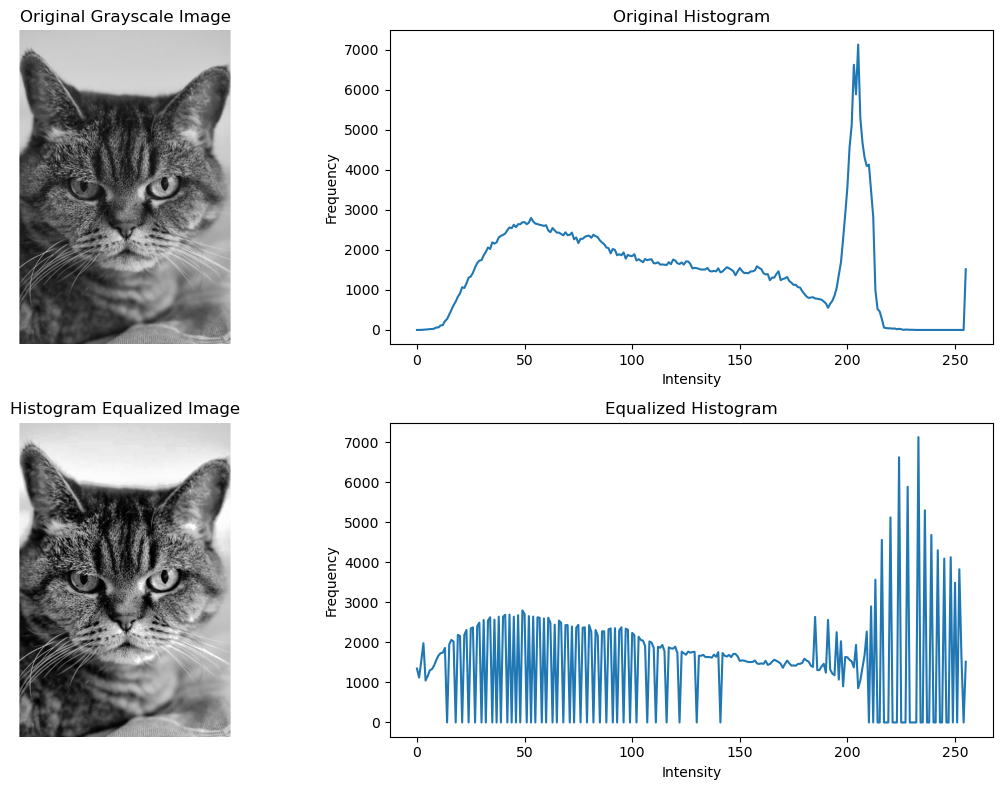

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

image = cv2.imread("cat.png")
height, width = image.shape[:2]
gray = np.zeros((height, width), dtype=np.uint8)
histogram = np.zeros(256, dtype=np.int32)

# Convert to grayscale and create the histogram manually.
for row in range(height):
    for col in range(width):
        blue = int(image[row, col, 0])
        green = int(image[row, col, 1])
        red = int(image[row, col, 2])
        value = int(0.114 * blue + 0.587 * green + 0.299 * red)
        gray[row, col] = value
        histogram[value] += 1

# Calculate the cumulative histogram manually.
cdf = np.zeros(256, dtype=np.int32)
cdf[0] = histogram[0]
for value in range(1, 256):
    cdf[value] = cdf[value - 1] + histogram[value]

# Find the first non-zero CDF value.
cdf_min = 0
for value in range(256):
    if cdf[value] != 0:
        cdf_min = cdf[value]
        break

total_pixels = height * width
equalized = np.zeros((height, width), dtype=np.uint8)

# Apply histogram equalization manually.
for row in range(height):
    for col in range(width):
        old_value = int(gray[row, col])
        if total_pixels == cdf_min:
            new_value = 0
        else:
            new_value = int(
                (cdf[old_value] - cdf_min) * 255 / (total_pixels - cdf_min)
            )
        equalized[row, col] = new_value

# Histogram of equalized image, calculated manually.
equalized_histogram = np.zeros(256, dtype=np.int32)
for row in range(height):
    for col in range(width):
        equalized_histogram[int(equalized[row, col])] += 1

plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.plot(histogram)
plt.title("Original Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")

plt.subplot(2, 2, 3)
plt.imshow(equalized, cmap="gray")
plt.title("Histogram Equalized Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.plot(equalized_histogram)
plt.title("Equalized Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()
